Notebook para encontar minimos de las funciones de Rastriguin, Ackley, Rosenbrock, Lévy, Griewank, Easom y el camello de tres jorobas; usando los métodos de BFGS, gradiente conjugado no lineal, Gauss-Newton y Lebenmerg-Marquart, así como las velocidades de convergencia de dichos métodos aplicados a cada función y para estimar algunos "radios" de algunas vecindades al rededor de los mínimos de cada función donde los métodos funcionan "bien".

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

El $ϵ$ de la computadora

In [ ]:
eps = np.finfo(float).eps

In [ ]:

def BFGS(f, x0, itermax, tol):
    """

    Parámetros:
    -----------
    f : función
        Función vectorial (gradiente o sistema).
    x0 : array-like
        Vector o punto inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada.

    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución.
    orbita : list
        Lista con el historial de puntos visitados.
    error : float
        Error final (norma del último paso).
    """
    # Garantizamos un vector unidimensional (1D)
    x0 = np.array(x0, dtype=float).flatten()

    # Evaluación inicial
    fx0 = f(x0)

    if np.linalg.norm(fx0) > tol:
        flag = 1
    else:
        flag = 0

    orbita = [x0.copy()]
    xk = x0.copy()
    iter_count = 1
    error = 0.0

    # Matriz identidad B = eye(length(x0))
    B = np.eye(len(x0))

    while flag == 1 and iter_count < itermax:
        fx0 = f(x0)

        # Cálculo del paso sk = -B \ f(x0)
        sk = -np.linalg.solve(B, fx0)

        # Actualización de la posición
        xk = x0 + sk
        error = np.linalg.norm(fx0) #(xk - x0)

        # Criterio de salida
        if error < ((np.linalg.norm(x0) + 1.0) * tol):
            flag = 0

        orbita.append(xk.copy())
        iter_count += 1

        # Diferencia de gradientes y actualización de B
        fxk = f(xk)
        yk = fxk - fx0

        # Equivalente a: Bk = B + yk*yk'/(yk'*sk) - B*sk*sk'*B/(sk'*B*sk)
        term1 = np.outer(yk, yk) / np.dot(yk, sk)

        B_sk = B @ sk
        term2 = np.outer(B_sk, B_sk) / np.dot(sk, B_sk)

        B = B + term1 - term2
        x0 = xk.copy()

    return xk, orbita, error

In [ ]:
def line_search_backtracking(f_obj, grad, x, d, c1=1e-4, rho=0.5):
    """
    Búsqueda de línea por backtracking satisfaciendo la condición de Armijo.
    """
    alpha = 1.0
    g = grad(x)

    # Condición de Armijo: f(x + alpha*d) <= f(x) + c1 * alpha * (g^T d)
    while f_obj(x + alpha * d) > f_obj(x) + c1 * alpha * np.dot(g, d):
        alpha *= rho
        if alpha < 1e-12:  # Prevenir bucle infinito por alta rigidez
            break

    return alpha

def Gradiente_Conjugado_NL(f_obj, grad, x0, itermax=1000, tol=1e-6, method='PR'):
    """
    Algoritmo de Gradiente Conjugado No Lineal.

    Parámetros:
    -----------
    f_obj : función
        Función escalar objetivo f(x) a minimizar.
    grad : función
        Gradiente vectorial g(x) = grad(f(x)).
    x0 : array-like
        Vector o punto de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia basada en la norma del gradiente ||g(x)||.
    method : str
        Fórmula para beta: 'PR' (Polak-Ribière) o 'FR' (Fletcher-Reeves).

    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Historial de los puntos xk visitados.
    error : float
        Norma del gradiente final ||g(xk)||.
    """
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]

    gk = grad(xk)
    dk = -gk.copy()

    iter_count = 0

    while np.linalg.norm(gk) > tol and iter_count < itermax:
        # 1. Encontrar la longitud de paso alpha mediante búsqueda de línea
        alpha = line_search_backtracking(f_obj, grad, xk, dk)

        # 2. Actualizar la solución
        xk = xk + alpha * dk
        orbita.append(xk.copy())

        # 3. Evaluar el nuevo gradiente
        gk_next = grad(xk)

        # 4. Calcular el parámetro beta de conjugación
        if method == 'PR':
            # Polak-Ribière con reinicio automático (PR+)
            num = np.dot(gk_next, gk_next - gk)
            den = np.dot(gk, gk)
            beta = max(0.0, num / den)
        elif method == 'FR':
            # Fletcher-Reeves
            beta = np.dot(gk_next, gk_next) / np.dot(gk, gk)
        else:
            beta = 0.0

        # 5. Actualizar la dirección de búsqueda
        dk = -gk_next + beta * dk

        # 6. Reinicio a la dirección del gradiente si se pierde la propiedad de descenso
        if np.dot(gk_next, dk) >= 0:
            dk = -gk_next

        gk = gk_next
        iter_count += 1

    return xk, orbita, np.linalg.norm(gk)

In [ ]:
def Gauss_Newton(r, x0, itermax, tol, J=None):
    """
    Algoritmo de Gauss-Newton para optimización por mínimos cuadrados no lineales
    o resolución de sistemas no lineales r(x) = 0.

    Parámetros:
    -----------
    r : función
        Función vectorial de residuos r(x).
    x0 : array-like
        Vector o punto de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada (norma del residuo o del paso).
    J : función, opcional
        Función que calcula la matriz Jacobiana J(x). Si es None, se aproxima
        numéricamente mediante diferencias finitas.

    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Lista con el historial de puntos xk visitados.
    error : float
        Norma del residuo final ||r(xk)||.
    """
    # Garantizar vector unidimensional de flotantes
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]

    # Función interna para aproximación numérica de la Jacobiana (diferencias finitas)
    def jacobiano_numerico(x, eps=1e-8):
        rx = r(x)
        m = len(rx)
        n = len(x)
        J_mat = np.zeros((m, n))
        for j in range(n):
            x_step = x.copy()
            x_step[j] += eps
            J_mat[:, j] = (r(x_step) - rx) / eps
        return J_mat

    iter_count = 0
    error = np.linalg.norm(r(xk))

    while error > tol and iter_count < itermax:
        rx = r(xk)

        # Evaluar la matriz Jacobiana analítica o numérica
        Jx = J(xk) if J is not None else jacobiano_numerico(xk)

        # Resolver el sistema J(x) * s = -r(x) en sentido de mínimos cuadrados
        # np.linalg.lstsq ofrece mayor estabilidad numérica que la inversión explícita
        sk, _, _, _ = np.linalg.lstsq(Jx, -rx, rcond=None)

        # Actualización de la solución
        xk = xk + sk
        orbita.append(xk.copy())

        # Criterio de parada basado en la magnitud del paso
        if np.linalg.norm(sk) < tol * (np.linalg.norm(xk) + 1.0):
            error = np.linalg.norm(r(xk))
            break

        error = np.linalg.norm(r(xk))
        iter_count += 1

    return xk, orbita, error

In [ ]:
def Levenberg_Marquardt(r, x0, itermax=1000, tol=1e-6, lam=1e-3, v=10.0, J=None):
    """
    Algoritmo de Levenberg-Marquardt para optimización de mínimos cuadrados no lineales.

    Parámetros:
    -----------
    r : función
        Función vectorial de residuos r(x).
    x0 : array-like
        Vector de estimación inicial.
    itermax : int
        Número máximo de iteraciones.
    tol : float
        Tolerancia para el criterio de parada.
    lam : float
        Parámetro de amortiguación inicial (lambda).
    v : float
        Factor multiplicador/divisor para ajustar lambda dinámicamente.
    J : función, opcional
        Función que calcula la matriz Jacobiana J(x). Si es None, se calcula
        por diferencias finitas.

    Retorna:
    --------
    xk : ndarray
        Aproximación de la solución del problema.
    orbita : list
        Historial de los puntos xk aceptados.
    error : float
        Norma del residuo final ||r(xk)||.
    """
    x0 = np.array(x0, dtype=float).flatten()
    xk = x0.copy()
    orbita = [xk.copy()]
    n = len(xk)

    # Función interna para aproximación numérica de la Jacobiana
    def jacobiano_numerico(x, eps=1e-8):
        rx = r(x)
        m = len(rx)
        J_mat = np.zeros((m, n))
        for j in range(n):
            x_step = x.copy()
            x_step[j] += eps
            J_mat[:, j] = (r(x_step) - rx) / eps
        return J_mat

    iter_count = 0
    rx = r(xk)
    cost_k = 0.5 * np.dot(rx, rx)

    while np.linalg.norm(rx) > tol and iter_count < itermax:
        # Evaluar la Jacobiana analítica o numérica
        Jx = J(xk) if J is not None else jacobiano_numerico(xk)

        JtJ = Jx.T @ Jx
        Jtr = Jx.T @ rx

        # Sistema modificado: (J^T J + lambda * I) s = -J^T r
        A = JtJ + lam * np.eye(n)

        try:
            sk = np.linalg.solve(A, -Jtr)
        except np.linalg.LinAlgError:
            sk, _, _, _ = np.linalg.lstsq(A, -Jtr, rcond=None)

        # Probar el nuevo punto candidato
        x_new = xk + sk
        r_new = r(x_new)
        cost_new = 0.5 * np.dot(r_new, r_new)

        # Evaluar si hubo mejora en la función de costo
        if cost_new < cost_k:
            # Aceptar paso y reducir parámetro de amortiguación lambda
            xk = x_new
            rx = r_new
            cost_k = cost_new
            lam = lam / v
            orbita.append(xk.copy())

            # Criterio de parada secundario basado en la magnitud del paso
            if np.linalg.norm(sk) < tol * (np.linalg.norm(xk) + 1.0):
                break
        else:
            # Rechazar paso e incrementar parámetro lambda para favorecer descenso de gradiente
            lam = lam * v

        iter_count += 1

    return xk, orbita, np.linalg.norm(rx)

Rastring:
$f(x,y)=20+x^2+y^2 -10\cos(2\pi x)-10\cos(2\pi y)$



In [ ]:
f_ras = lambda X: 20 + X[0]**2 + X[1]**2 - 10*np.cos(2*np.pi*X[0]) - 10*np.cos(2*np.pi*X[1])

gradf_ras = lambda X: np.array([2*X[0] + 20*np.pi*np.sin(2*np.pi*X[0]),
                                2*X[1] + 20*np.pi*np.sin(2*np.pi*X[1])])

Ackley:
$f(x,y)=-20\exp{(
-0.2\sqrt{\frac{x^2+y^2}{2}})}-\exp{(
\frac{\cos(2\pi x)+\cos(2\pi y)}{2})}+20+e$

Importante: ajuste su gradiente y hessiana sumando $ϵ$ en dónde habria una división por 0, pues esta función no es diferenciable en $(0,0)$  


In [ ]:
f_acl = lambda X: -20*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2)) - np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2) + 20 + np.e

gradf_acl = lambda X: np.array([
2*X[0]*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) + np.pi*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*np.sin(2*np.pi*X[0]),
2*X[1]*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) + np.pi*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*np.sin(2*np.pi*X[1])])

Rosenbrock:
$f(x,y)=100(y-x^2)^2+(1-x)^2$


In [ ]:
f_ros = lambda X: 100*(X[1] - X[0]**2)**2 + (1 - X[0])**2

gradf_ros = lambda X: np.array([-400*X[0]*(X[1] - X[0]**2) - 2*(1 - X[0]),
                                200*(X[1] - X[0]**2)])

Lévy:
$
f(x,y)=\sin^2(3\pi x)+(x-1)^2 (1+\sin^2(3\pi y))+(y-1)^2(1+\sin^2(2\pi y))
$

In [ ]:
f_lev = lambda X: np.sin(3*np.pi*X[0])**2 + (X[0] - 1)**2*(1 + np.sin(3*np.pi*X[1])**2) + (X[1] - 1)**2*(1 + np.sin(2*np.pi*X[1])**2)

gradf_lev = lambda X: np.array([3*np.pi*np.sin(6*np.pi*X[0]) + 2*(X[0] - 1)*(1 + np.sin(3*np.pi*X[1])**2),
                                3*np.pi*(X[0] - 1)**2*np.sin(6*np.pi*X[1]) + 2*(X[1] - 1)*(1 + np.sin(2*np.pi*X[1])**2) + 2*np.pi*(X[1] - 1)**2*np.sin(4*np.pi*X[1])])

Griewank:
$
f(x,y)=1+\frac{x^2+y^2}{4000}
-\cos(x)\cos\left(\frac{y}{\sqrt{2}}\right)
$

In [ ]:
f_gri = lambda X: 1 + (X[0]**2 + X[1]**2)/4000 - np.cos(X[0])*np.cos(X[1]/np.sqrt(2))

gradf_gri = lambda X:  np.array([X[0]/2000 + np.sin(X[0])*np.cos(X[1]/np.sqrt(2)),
                                 X[1]/2000 + np.cos(X[0])*np.sin(X[1]/np.sqrt(2))/np.sqrt(2)])

Easom:
$
f(x,y)=-\cos(x)\cos(y)
\exp\left(- (x-\pi)^2-(y-\pi)^2\right)
$

In [ ]:
f_eas = lambda X: -np.cos(X[0])*np.cos(X[1])*np.exp(-(X[0] - np.pi)**2 - (X[1] - np.pi)**2)

gradf_eas = lambda X: np.array([np.exp(-(X[0] - np.pi)**2 - (X[1] - np.pi)**2)*np.cos(X[1])*(np.sin(X[0]) + 2*(X[0] - np.pi)*np.cos(X[0])),
                                np.exp(-(X[0] - np.pi)**2 - (X[1] - np.pi)**2)*np.cos(X[0])*(np.sin(X[1]) + 2*(X[1] - np.pi)*np.cos(X[1]))])

Camello:
$
f(x,y)=2x^2-1.05x^4+\frac{x^6}{6}+xy+y^2
$

In [ ]:
f_cam = lambda X: 2*X[0]**2 - 1.05*X[0]**4 + X[0]**6/6 + X[0]*X[1] + X[1]**2

gradf_cam = lambda X: np.array([4*X[0] - 4.2*X[0]**3 + X[0]**5 + X[1], X[0] + 2*X[1]])

Func guarda cada función, Grad guarda los gradientes de cada función,
, además la longitud de cada uno nos dice el número de funciones en el código.

NFun y NMet sirven para dar indices a las funciones, por ejemplo: el método con índice 2 es NMet[2] y la función con índice 4 es NFun[4]


In [ ]:
Func = [f_ras,f_acl,f_ros,f_lev,f_gri,f_eas,f_cam]
Grad = [gradf_ras,gradf_acl,gradf_ros,gradf_lev,gradf_gri,gradf_eas,gradf_cam]
Met  = [BFGS,Gradiente_Conjugado_NL,Gauss_Newton,Levenberg_Marquardt]

NFun = ["Rastring","Ackley","Rosenbrock","Levy","Griewank","Easom","Camello"]
NMet = ["BFGS","NLCG","GN","LM"]

Parametros:
$kmax, tol$ son los mismos para todas las funciones, mientras que $x_0$ cambia para cada una de ellas (y se especifican en la lista X0)

In [ ]:
X0 = [np.array([.2, .1]),
      np.array([.3, .2]),
      np.array([0.8, 0.9]),
      np.array([1.1, 1.2]),
      np.array([.3, .1]),
      np.array([3., 3.]),
      np.array([.2, .3])]
kmax = 1e3
tol = 1.e-9

mins, orbs son arreglos que guardan los minimos y la orbita de cada función con cierto método, es decir, mins[i][j][1] es el mínimo de la función i calculado con el método j y orbs[i][j][1] es la orbita de la función i calculada on el método j.

In [ ]:
mins = [None]*len(Func)
orbs = [None]*len(Func)
for i in range (len(Func)):
  mins[i] = [None]*len(Met)
  orbs[i] = [None]*len(Met)

for i in range(len(Func)):
  for j in range(len(Met)):
    if (j != 1):
      min,orb,_ = Met[j](Grad[i],X0[i],kmax,tol)
      mins[i][j] = [NMet[j],min]
      orbs[i][j] = [NMet[j],orb]
    else:
      min,orb,_  = Met[j](Func[i],Grad[i],X0[i],kmax,tol)
      mins[i][j] = [NMet[j],min]
      orbs[i][j] = [NMet[j],orb]

In [ ]:
print(mins[1][1])

['NLCG', array([1.63756271e-10, 4.44379484e-10])]


Aqui se crea errs, contiene la norma-2 de los errores, aquí se invierte la forma en que se lee errs[i][j] con respecto a mins u orbs, pues para mí es más natural pensar que el error le "pertenece" al método y no a la función; así errs[i][j] es un arreglo que guarda la norma-2 de los errores del método i aplicado a la función j; así e[i][j][k] es lo que denotare como $||e^{(k)}||$.

In [ ]:
errs = [None]*len(Met)
for i in range(len(Met)):
  errs[i] = [None]*len(Func)
  for j in range(len(Func)):
    errs[i][j] = [None]*len(orbs[j][i][1][:-1])
    for k in range(len(orbs[j][i][1][:-1])):
       errs[i][j][k] = float(np.linalg.norm(orbs[j][i][1][k]-mins[j][i][1]))

En esta celda se calculan las velocidades de convergencia de cada método para cada función:

Primero para cada i,j (en NMet y en NFun) se filtran los arreglos e[i][j] quitandoles sus elementos menores que $ϵ
$. Luego las lista X[i][j],Y[i][j] basicamente son ln(e[i][j]), donde (X[i][j][k],Y[i][j][k]) representa el par $(ln(||e^{(k)}||),ln(||e^{(k+1)})||)$ del método i aplicado a la función j, procurando que para cada método y para cada función sean solo los ultimos 5 puntos; si es que hay al menos 6 elementos en errs[i][j] una vez que se filtrarón los datos, si no, se toman todos los puntos en errs[i][j] para construir X[i][j],Y[i][j] y obtener la regresion, esto si errs[i][j] tiene mas o igual que 2 elementos. Con eso es posible obtener el ajuste lineal que mejor aproxima los puntos y con ellos la velocidad de convergencia (la pendiente de dicho ajuste). Si además ocurre que el numero de iteraciones fue kmax, es porque el método no convergio y se avisa y no se calcula su velocidad de convergencia y si en errs[i][j] hay menos de dos datos, pues no es posible hacer regresión lineal y se informa.


In [ ]:
X = [None]*len(Met)
Y = [None]*len(Met)
P = [None]*len(Met)

for i in range(len(Met)):
    X[i] = [None]*len(Func)
    Y[i] = [None]*len(Func)
    P[i] = [None]*len(Func)
    for j in range(len(Func)):
        err = np.array(errs[i][j])
        #mask = (err[:-1] > eps) & (err[1:] > eps)
        #X[i][j] = np.log(err[:-1][mask])
        #Y[i][j] = np.log(err[1:][mask])
        err = err[err > eps]
        if len(err) >= 6:
            X[i][j] = np.log(err[-6:-1])
            Y[i][j] = np.log(err[-5:])
            P[i][j],_ = np.polyfit(X[i][j],Y[i][j],1)
        elif len(err) >= 2:
            X[i][j] = np.log(err[:-1])
            Y[i][j] = np.log(err[1:])
            P[i][j],_ = np.polyfit(X[i][j],Y[i][j],1)
        elif len(orbs[j][i][1]) == kmax:
            P[i][j] = "No convergió"
        else:
            P[i][j] = "Datos insuficientes"

/tmp/ipykernel_4816/3940831595.py:18: RankWarning: Polyfit may be poorly conditioned
  P[i][j],_ = np.polyfit(X[i][j],Y[i][j],1)


Se imprimen las velocidades de convergencia de cada método para cada función.

In [ ]:
for i in range(len(Met)):
  print("El método ",NMet[i]," aplicado a la función de")
  for j in range(len(Func)):
   print("  ",NFun[j]," tiene velocidad de convergencia de ",P[i][j])

El método  BFGS  aplicado a la función de
   Rastring  tiene velocidad de convergencia de  1.2556311458764675
   Ackley  tiene velocidad de convergencia de  1.2730950625751316
   Rosenbrock  tiene velocidad de convergencia de  1.786273793398126
   Levy  tiene velocidad de convergencia de  1.4521054085217557
   Griewank  tiene velocidad de convergencia de  1.236143358774344
   Easom  tiene velocidad de convergencia de  1.7987511765665474
   Camello  tiene velocidad de convergencia de  1.4529913263259329
El método  NLCG  aplicado a la función de
   Rastring  tiene velocidad de convergencia de  1.0025907191429455
   Ackley  tiene velocidad de convergencia de  -1.0250668555273865
   Rosenbrock  tiene velocidad de convergencia de  0.3366227065903617
   Levy  tiene velocidad de convergencia de  0.852747923113271
   Griewank  tiene velocidad de convergencia de  1.1206253815549796
   Easom  tiene velocidad de convergencia de  0.49999999999999983
   Camello  tiene velocidad de convergencia de  



*   BFGS: En general tuvo convergencia super lineal
*   NLCG: Vemos que para las funciones de Rastring y de Griewank tuvo convergencia lineal y superlineal, respectivamente. Para la función de Ackley vemos una pendiente negativa lo cual fue consecuencia de que sus errores oscilan, como se ve en la siguiente celda. Mientras que las otras funciones son menos que lineales.
*   GN: Tuvo el mejor desempeño pues tuvo convergencia cubica dos veces y en la mayoría de funciones presentó convergencia super cuadrática. Solo con la función de Ackley obtuvo una velocidad menor a dos que es de esperarse pues es la función más patológica.
*   LM: Es el segundo método con las velocidades de convergencia más altas, muy similar a las de GN, solo que con la función de Ackley tuvo una velocidad ligeramente menor que con GN.

['NLCG', array([1.63756271e-10, 4.44379484e-10])]
1001


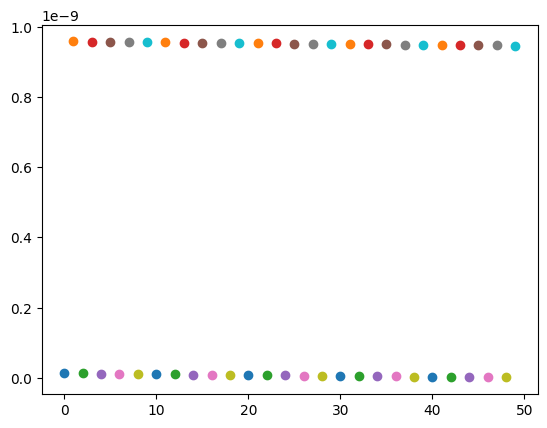

In [ ]:
print(mins[1][1])
print(len(orbs[1][1][1]))

for k in range(50):
  plt.plot(k,errs[1][1][len(errs[1][1])-50+k],'o')

Para estimar el radio $r_{i,j}$ de $B_{r_{i,j}}(x^*)$, donde el método i-esimo se comporta "bien" y donde $x^*$ es el mínimo cálculado con el método i aplicado a la función j se prueba con varios radios y varios ángulos, es decir para cada radio r' dentro de cierto dominio discreto (en este caso la partición del intervalo del intervalo $[0.01,2]$ en 100 puntos x-espaciados) se toma un punto $x_{temp}$ de la $Fr(B_{r'}(x^*))$ y se usa como aproximación inicial para el método i aplicado a la función j con los mismos parametros de antes, la cual, devuelve un punto crítico $x_k$ de la función j, y se verifica si es que $||x_k-x^*||_2\leq\sqrt{tol}$. Si es que para algún $r'$ sucede que $||x_k-x^*||_2\ > \sqrt{tol}$, entonces se elige al $r'$ anterior a él como un posible radio satisfactorio. En este caso, el proceso se repite 16 veces, para cada método y para cada función, escogiendo en cada caso a $x_{temp}$ en dirección de $(\cos{θ},\sin{θ})$ pensando a $x^*$ como si fuera el origen y donde $θ∈[0,2π)$ (donde $[0,2π)$ representa la partición del intervalo real $[0,2π)$ con 16 puntos x-espaciados). Una vez obtenidos los 16 puntos, se escoge al minimo de ellos y ese es el valor $r$ buscado.

Si resulta que para algún angulo y para r'=0.01, $x_k$ no cumplio que $||x_k-x^*||_2\leq\sqrt{tol}$, entinces tomamos r=0.

In [ ]:
rmax = 2.
pasos = 100
Rs = np.linspace(.01, rmax, pasos)
Angs = np.linspace(0, 2*np.pi, 16, endpoint=False)
kmax_r = 1e2

R = [None]*len(Met)
for i in range(len(Met)):
    R[i] = [None]*len(Func)
    for j in range(len(Func)):
        xstar = np.array(mins[j][i][1])
        pr = []
        for a in Angs:
            r_bueno = 0.
            for r in Rs:
                xtemp = xstar + r*np.array([np.cos(a), np.sin(a)])
                if (i != 1):
                    xk,_,_ = Met[i](Grad[j],xtemp,kmax,tol)
                else:
                    xk,_,_ = Met[i](Func[j],Grad[j],xtemp,kmax_r,tol)
                if (np.all(np.isfinite(xk)) and
                    np.linalg.norm(xk-xstar) <= np.sqrt(tol)):
                    r_bueno = float(r)
                else:
                    break
            pr.append(r_bueno)
        R[i][j] = np.min(pr)

/tmp/ipykernel_316/3946621697.py:65: RuntimeWarning: invalid value encountered in divide
  term1 = np.outer(yk, yk) / np.dot(yk, sk)


In [ ]:
for i in range(len(Met)):
  print("Una buena vecindad para el método de ",NMet[i]," aplicado a la función de:")
  for j in range(len(Func)):
   print("  ",NFun[j]," al rededor del minimo: " ,mins[j][i][1]," tiene radio ",R[i][j])

Una buena vecindad para el método de  BFGS  aplicado a la función de:
   Rastring  al rededor del minimo:  [-22.87022921 -24.8547411 ]  tiene radio  0.0
   Ackley  al rededor del minimo:  [-10817.50000005 -28544.50000003]  tiene radio  0.0301010101010101
   Rosenbrock  al rededor del minimo:  [1. 1.]  tiene radio  0.0904040404040404
   Levy  al rededor del minimo:  [1.85296183 0.17167905]  tiene radio  0.0
   Griewank  al rededor del minimo:  [1.17919234e-14 1.41846045e-15]  tiene radio  1.557777777777778
   Easom  al rededor del minimo:  [3.14159265 3.14159265]  tiene radio  0.9145454545454546
   Camello  al rededor del minimo:  [ 6.74808623e-20 -5.63368730e-19]  tiene radio  0.29141414141414146
Una buena vecindad para el método de  NLCG  aplicado a la función de:
   Rastring  al rededor del minimo:  [9.97831416e-10 1.25817350e-09]  tiene radio  0.0703030303030303
   Ackley  al rededor del minimo:  [1.63756271e-10 4.44379484e-10]  tiene radio  0.5527272727272727
   Rosenbrock  al rede

La función de Easom con los métodos de GN y LM fue la que practicamente tuvo el mismo radio con esos métodos y con el de Newton.